# Two rounds of the repetition code, step by step: Questions 1, 2 and 3

> **In short.**
> * **The program.** The paper's running example: the round of repetition-code checks of [WhichCodeStepByStep.ipynb](WhichCodeStepByStep.ipynb) (ancillas measure $X_0X_1$ into $a$ and $X_1X_2$ into $b$, then a correction: $Z$ on qubit 0 iff $a = 1, b = 0$, on qubit 1 iff $a = b = 1$, on qubit 2 iff $a = 0, b = 1$), run twice, with a Pauli error $E$ between the rounds. Round 2 writes its results $a', b'$ to a second register `d`. Here $E = Z_0Z_1$; the last section runs all 36 one- and two-qubit errors.
> * **Why two rounds.** Question 1 (which code?) needs one round. Question 2 (what does a block do to the encoded qubit?) needs a code *before* the block: round 1 makes it, and round 2 is the block. Question 3 (is it the same in every run?) needs detectors: round 2 repeats the checks, so its results are fixed by round 1 and the error.
> * **The steps.** (1) The program. (2) Question 1: the code after every stage. (3) The block. (4)–(7) Question 2, the four steps of `logical_action`: build and glue the encoders, reduce, name, check. (8) Question 3: the runs and the detectors. (9) All 36 errors.
> * **Library calls only**: PyZX's OpenQASM reader, `QProgram`, `code_at`, `group_stages`, `logical_action`, `encoder`, `draw_program`, `draw_graph`, `to_gpf_steps`, `reduce_gpf`, `phases_modulo`, `consistent_assignments`.

In [1]:
%matplotlib inline
import itertools
import numpy as np
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.utils import VertexType
from zxqec.qprogram import QProgram
from zxqec.gpf import consistent_assignments, phases_modulo, reduce_gpf, to_gpf_steps
from zxqec.spacetime import Topology, draw_graph, draw_program

## 1. The program

The OpenQASM text, read by PyZX, one stage per piece. Qubits 0–2 are the data qubits (inputs of the program); ancillas 3 and 4 start in $|0\rangle$ and sit between the data qubits they check.

In [2]:
HEADER = '''OPENQASM 2.0;
include "qelib1.inc";
qreg q[5];         // data 0-2, ancillas 3, 4
creg c[2];         // c[0] = a, c[1] = b
creg d[2];         // d[0] = a', d[1] = b'
'''
ROUND = '''h q[3]; h q[4];
cx q[3], q[0]; cx q[3], q[1];  // X0 X1
cx q[4], q[1]; cx q[4], q[2];  // X1 X2
h q[3]; h q[4];
measure q[3] -> c[0];
measure q[4] -> c[1];
'''
CORRECTION = '''if(c==1) z q[0];   // a = 1, b = 0
if(c==3) z q[1];   // a = 1, b = 1
if(c==2) z q[2];   // a = 0, b = 1
'''
ROUND_2 = 'reset q[3]; reset q[4];\n' + ROUND.replace('c[', 'd[')
CORRECTION_2 = CORRECTION.replace('if(c', 'if(d')
ERROR = 'z q[0]; z q[1];\n'                       # E = Z0 Z1

chip = Topology()
for q, xy in {0: (0, 0), 1: (1, 0), 2: (2, 0), 3: (0.5, 1), 4: (1.5, 1)}.items():
    chip.add_node(q, xy)
for ancilla, data in [(3, 0), (3, 1), (4, 1), (4, 2)]:
    chip.add_edge(ancilla, data)

p = QProgram(5, bits=4, initial_states={3: '0', 4: '0'}, topology=chip)
for stage, text in [('round 1', ROUND), ('correct 1', CORRECTION), ('error', ERROR),
                    ('round 2', ROUND_2), ('correct 2', CORRECTION_2)]:
    p.add_circuit(Circuit.from_qasm(HEADER + text), name=stage)
print(HEADER + ROUND + CORRECTION + ERROR + ROUND_2 + CORRECTION_2)

OPENQASM 2.0;
include "qelib1.inc";
qreg q[5];         // data 0-2, ancillas 3, 4
creg c[2];         // c[0] = a, c[1] = b
creg d[2];         // d[0] = a', d[1] = b'
h q[3]; h q[4];
cx q[3], q[0]; cx q[3], q[1];  // X0 X1
cx q[4], q[1]; cx q[4], q[2];  // X1 X2
h q[3]; h q[4];
measure q[3] -> c[0];
measure q[4] -> c[1];
if(c==1) z q[0];   // a = 1, b = 0
if(c==3) z q[1];   // a = 1, b = 1
if(c==2) z q[2];   // a = 0, b = 1
z q[0]; z q[1];
reset q[3]; reset q[4];
h q[3]; h q[4];
cx q[3], q[0]; cx q[3], q[1];  // X0 X1
cx q[4], q[1]; cx q[4], q[2];  // X1 X2
h q[3]; h q[4];
measure q[3] -> d[0];
measure q[4] -> d[1];
if(d==1) z q[0];   // a = 1, b = 0
if(d==3) z q[1];   // a = 1, b = 1
if(d==2) z q[2];   // a = 0, b = 1



The ZX-diagram of the program, each stage in its own colour (`draw_program` with level 0, whose blocks are the stages). Each CNOT is a green spider on the ancilla joined to a red spider on the data qubit; a blue edge is a Hadamard; a measurement is a red spider whose phase is its result; a correction is a green spider on a data qubit whose phase is its condition (`c[0] + c[0]⋅c[1]` is $a(1-b)$); the error is the green $\pi$ on qubits 0 and 1.

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


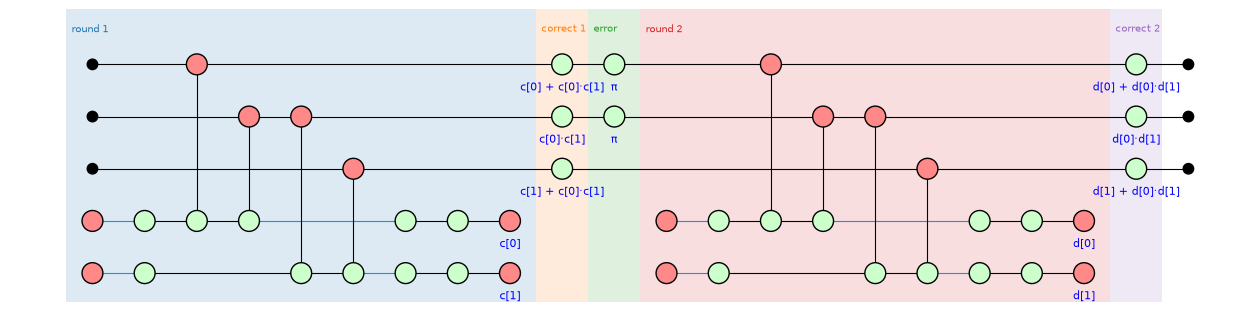

In [3]:
draw_program(p, 0, time_axis=False, show_time=False, even_rows=True, labels_above=True, figsize=(16, 3.8))

## 2. Question 1: the code after every stage

`code_at(stage)` cuts the program after that stage and reads the code of the data qubits (as in [WhichCodeStepByStep.ipynb](WhichCodeStepByStep.ipynb)). After round 1 the signs are the results; the correction makes them $+$; the error flips the sign of every check that contains an odd number of its $Z$s; round 2 measures them, and its correction makes them $+$ again in every run the detectors allow (section 8).

In [4]:
for stage in range(p.num_stages):
    print("after stage {} ({}):".format(stage, p.stages[stage].name))
    print(p.code_at(stage))

after stage 0 (round 1):
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer (-1)^(c[0])XXI
    stabilizer (-1)^(c[1])IXX
    logical X XII   logical Z ZZZ
after stage 1 (correct 1):
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +XXI
    stabilizer +XIX
    logical X XII   logical Z ZZZ
after stage 2 (error):
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +XXI
    stabilizer -XIX
    logical X XII   logical Z ZZZ
after stage 3 (round 2):
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +XXI
    stabilizer -XIX
    logical X XII   logical Z ZZZ
after stage 4 (correct 2):
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer (-1)^(d[0])XXI
    stabilizer (-1)^(d[1] + 1)IXX
    logical X XII   logical Z ZZZ


## 3. The block

Round 1 with its correction is one block; the error, round 2 and its correction are the next. Question 2 asks what the second block does to the encoded qubit, from the code before it, $C_\mathrm{in}$ (`code_at(1)`), to the code after it, $C_\mathrm{out}$ (`code_at(4)`). Both are read by the tool, as above.

Level 2 (2 blocks):
  Block 0 'round 1': [round 1, correct 1]
  Block 1 'error + round 2': [error, round 2, correct 2]
the block: 23 spiders, 29 vertices


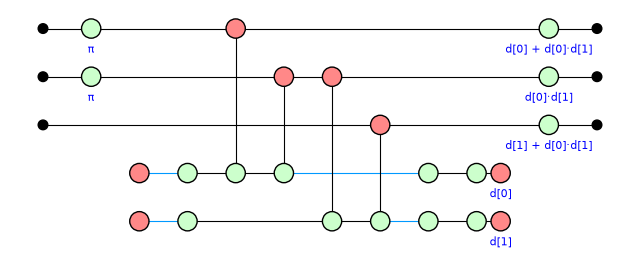

In [5]:
level = p.group_stages([(0, 1, 'round 1'), (2, 4, 'error + round 2')])
print(p.describe_level(level))
action = p.logical_action(level, 1)
B = action.block
print("the block:", sum(1 for v in B.vertices() if B.type(v) != VertexType.BOUNDARY), "spiders,",
      B.num_vertices(), "vertices")
draw_graph(B, time_axis=False, show_time=False, figsize=(8, 3))

## 4. Question 2, step 1: build and glue the encoders

The encoder of $C_\mathrm{in}$, $E_\mathrm{in}$, from its stabilizers and logical operators: a green spider on the input joined to the red spider of qubit 0 ($\bar X = X_0$), a green spider for each $X$ stabilizer, a red spider on each output.

C_in:
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer +XXI
    stabilizer +XIX
    logical X XII   logical Z ZZZ
E_in: 6 spiders, 9 edges


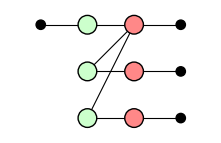

In [6]:
code_in, code_out = p.code_at(1), p.code_at(4)
print("C_in:"); print(code_in)
E_in = code_in.encoder()
print("E_in:", sum(1 for v in E_in.vertices() if E_in.type(v) != VertexType.BOUNDARY), "spiders,", E_in.num_edges(), "edges")
zx.draw_matplotlib(E_in, figsize=(2.6, 1.6))

The decoder of $C_\mathrm{out}$, $E_\mathrm{out}^\dagger$: the adjoint of its encoder. Its green spiders carry the signs of $C_\mathrm{out}$, `d[0]` and `d[1] + 1`.

C_out:
[[3, 1, 1]] CSS code on qubits 0, 1, 2
    stabilizer (-1)^(d[0])XXI
    stabilizer (-1)^(d[1] + 1)IXX
    logical X XII   logical Z ZZZ


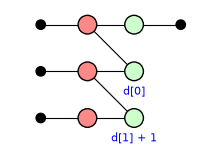

In [7]:
print("C_out:"); print(code_out)
zx.draw_matplotlib(code_out.encoder().adjoint(), figsize=(2.6, 1.6))

Glued together, $E_\mathrm{out}^\dagger\, B\, E_\mathrm{in}$: the encoder on the left, the block in the middle, the decoder on the right. This is the diagram `logical_action` reduces.

the composite: 37 vertices


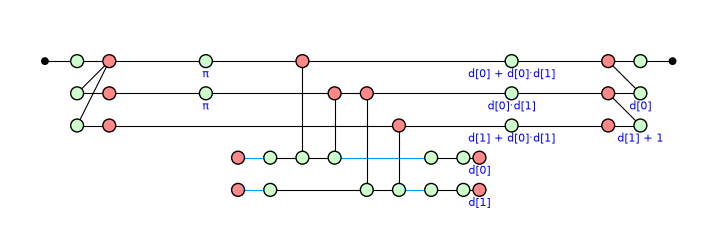

In [8]:
composite = action.composite
print("the composite:", composite.num_vertices(), "vertices")
draw_graph(composite, time_axis=False, show_time=False, figsize=(9, 3))

## 5. Question 2, step 2: reduce

`reduce_gpf` rewrites the composite into two layers. `to_gpf_steps` records the stages of its first part; the row reduction after it changes nothing here.

In [9]:
stages = to_gpf_steps(composite.copy())
for what, g in stages:
    print("{:3d} vertices: {}".format(g.num_vertices(), what))
print("{:3d} vertices after reduce_gpf".format(action.graph.num_vertices()))

 37 vertices: the diagram
 19 vertices: identity spiders removed, neighbours of the same colour fused
 15 vertices: Hadamard edges pushed to the boundary wires, spiders fused
 15 vertices: phases that are not Pauli moved onto gadgets
  4 vertices: the bialgebra rule applied until two layers remain
  4 vertices: one Z-spider per input and one X-spider per output: the normal form
  4 vertices after reduce_gpf


After spiders are fused and the Hadamard edges moved to the boundary wires:

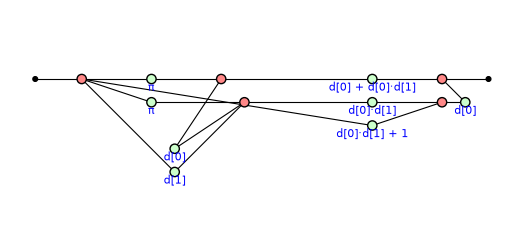

In [10]:
zx.draw_matplotlib(stages[2][1], figsize=(6.5, 3))

The two layers left after the bialgebra rule: one spider on the input, one on the output, and the results only in a phase.

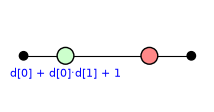

In [11]:
zx.draw_matplotlib(stages[-1][1], figsize=(2.5, 1.2))

The reduction also returns the **detectors**, here parities of results that are 0 in every run. They fix $a' = 0$, $b' = 1$: the syndrome of a $Z$ on qubit 2. Round 2 sees $Z_0Z_1$ as a $Z$ on qubit 2. With the phase written modulo the detectors, the wire carries a green $\pi$: a $Z$ on the logical qubit.

detectors: d[0], d[1] + 1


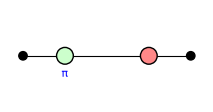

In [12]:
print("detectors:", ', '.join(str(d) for d in action.detectors))
zx.draw_matplotlib(phases_modulo(action.graph, action.result.constraints), figsize=(2.5, 1.2))

## 6. Question 2, step 3: name

The matrix depends on the results only through the phases left in the reduced diagram; runs that give them the same values form one *class*. Here no phase depends on a result once the detectors are used, so there is one class. For it the tool picks one run the detectors allow, substitutes it, evaluates the $2 \times 2$ matrix, and names it as an operation $G$ followed by a Pauli correction $P$.

In [13]:
for b in action.branches():
    print("class:", b.when())
    print("run:", b.outcomes)
    print("matrix:", (np.round(action.matrix(b.outcomes).real, 3) + 0.0).tolist())
    print("G = {}, P = {}".format(b.operation, b.correction))

class: in every run
run: {'d[0]': 0, 'd[1]': 1}
matrix: [[1.0, 0.0], [0.0, -1.0]]
G = I, P = Z


$\mathrm{diag}(1, -1)$ is $Z$: the block does nothing to the encoded qubit but leave a logical $Z$ error. Round 2's correction applied $Z$ to qubit 2, completing $Z_0Z_1$ to $Z_0Z_1Z_2 = \bar Z$.

## 7. Question 2, step 4: check that the block keeps the code

Only if the block maps $C_\mathrm{in}$ into $C_\mathrm{out}$ is this matrix what it does to the encoded qubit.

In [14]:
print("stays in the code:", action.stays_in_code())

stays in the code: True


## 8. Question 3: the runs and the detectors

The whole program has four results. Round 1's are random; round 2's are fixed by the error. The detectors of the whole program say which runs can occur: `consistent_assignments` lists them.

In [15]:
whole = reduce_gpf(p.quantum_graph())
print("detectors of the whole program:", ', '.join(str(d) for d in whole.detectors))
for run in consistent_assignments(whole.detectors, ['c[0]', 'c[1]', 'd[0]', 'd[1]']):
    print("  possible run:", run)

detectors of the whole program: d[0], d[1] + 1
  possible run: {'c[0]': 0, 'c[1]': 0, 'd[0]': 0, 'd[1]': 1}
  possible run: {'c[0]': 0, 'c[1]': 1, 'd[0]': 0, 'd[1]': 1}
  possible run: {'c[0]': 1, 'c[1]': 0, 'd[0]': 0, 'd[1]': 1}
  possible run: {'c[0]': 1, 'c[1]': 1, 'd[0]': 0, 'd[1]': 1}


Four runs, one for each $a, b$; in all of them $a' = 0$, $b' = 1$. Question 3 asks whether the block does the same in every run. Its verdict:

In [16]:
print(action.verdict())
print("deterministic:", action.is_deterministic())

deterministic up to a Pauli frame: every run implements I followed by a Pauli correction (Z) that the outcomes determine
deterministic: True


## 9. All 36 errors

The same four steps for every one- and two-qubit Pauli error between the rounds, grouped by what round 2 reads and what is left on the encoded qubit ($P$, with $G = I$ in every case). In every case the block keeps the code and is deterministic.

In [17]:
PAULI = {'X': 'x q[{0}];\n', 'Y': 'z q[{0}]; x q[{0}];\n', 'Z': 'z q[{0}];\n'}
errors = {'none': ''}
errors.update({l + str(q): PAULI[l].format(q) for q in range(3) for l in 'XYZ'})
errors.update({l1 + str(q1) + l2 + str(q2): PAULI[l1].format(q1) + PAULI[l2].format(q2)
               for q1, q2 in itertools.combinations(range(3), 2) for l1 in 'XYZ' for l2 in 'XYZ'})
groups = {}
for name, text in errors.items():
    q = QProgram(5, bits=4, initial_states={3: '0', 4: '0'}, topology=chip)
    for stage, piece in [('round 1', ROUND), ('correct 1', CORRECTION), ('error', text),
                         ('round 2', ROUND_2), ('correct 2', CORRECTION_2)]:
        q.add_circuit(Circuit.from_qasm(HEADER + piece), name=stage)
    act = q.logical_action(q.group_stages([(0, 1, 'round 1'), (2, 4, 'error + round 2')]), 1)
    assert act.stays_in_code() and act.is_deterministic()
    assert {b.operation for b in act.branches()} == {'I'}
    left = ','.join(sorted({b.correction or 'I' for b in act.branches()}))
    reads = ','.join("{}{}".format(r['d[0]'], r['d[1]'])
                     for r in consistent_assignments(reduce_gpf(q.quantum_graph()).detectors, ['d[0]', 'd[1]']))
    groups.setdefault((left, reads), []).append(name)
print(len(errors) - 1, "errors")
for (left, reads), names in sorted(groups.items()):
    print("  round 2 reads a'b' = {}  left: {}  <- {}".format(reads, left, ' '.join(names)))

36 errors
  round 2 reads a'b' = 00  left: I  <- none X0X1 X0X2 X1X2
  round 2 reads a'b' = 01  left: I  <- Z2 X0Y2 X1Y2
  round 2 reads a'b' = 10  left: I  <- Z0 Y0X1 Y0X2
  round 2 reads a'b' = 11  left: I  <- Z1 X0Y1 Y1X2
  round 2 reads a'b' = 00  left: X  <- X0 X1 X2
  round 2 reads a'b' = 01  left: X  <- Y2 X0Z2 X1Z2
  round 2 reads a'b' = 10  left: X  <- Y0 Z0X1 Z0X2
  round 2 reads a'b' = 11  left: X  <- Y1 X0Z1 Z1X2
  round 2 reads a'b' = 01  left: Y  <- Y0Z1 Z0Y1
  round 2 reads a'b' = 10  left: Y  <- Y1Z2 Z1Y2
  round 2 reads a'b' = 11  left: Y  <- Y0Z2 Z0Y2
  round 2 reads a'b' = 01  left: Z  <- Y0Y1 Z0Z1
  round 2 reads a'b' = 10  left: Z  <- Y1Y2 Z1Z2
  round 2 reads a'b' = 11  left: Z  <- Y0Y2 Z0Z2


A single $Z$ is corrected; an $X$ is not seen and is left as a logical $X$; two $Z$s look like a $Z$ on the third qubit, whose correction completes $\bar Z$. The code corrects one $Z$ error and no $X$ error.

## Summary

| step | what the tool does | here ($E = Z_0Z_1$) |
|---|---|---|
| Q1 | read the code after each stage (`code_at`) | the repetition code; signs = results after a round, $+$ after a correction |
| block | group the stages (`group_stages`) | error + round 2 + correction |
| Q2.1 | build $E_\mathrm{in}$ and $E_\mathrm{out}^\dagger$ from the codes, glue them around the block | 37 vertices |
| Q2.2 | reduce (`reduce_gpf`) | 4 vertices; detectors fix $a'b' = 01$ |
| Q2.3 | one run per class, its matrix, its name | one class: $G = I$, $P = Z$ |
| Q2.4 | check the block keeps the code (`stays_in_code`) | yes |
| Q3 | the runs the detectors allow; the same in every run? (`verdict`) | four runs ($a, b$ free); deterministic up to a Pauli frame |